### VIX index correlation V2

In [ ]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm

from scipy.stats import spearmanr
from scipy.stats import pearsonr
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.request_api_v2 import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension
from Modules.fibonacci_retracement import FibonacciRetracement
from Modules.fibonacci_extension import FibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
fred_url = "https://api.stlouisfed.org/fred/series/observations"
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()
# Fibonacciエクステンションをプロットするクラスのインスタンスを作成
fibonacci_extension_v2 = FibonacciExtension() 
# Fibonacciリトレースメントを計算するクラスのインスタンスを作成
fibonacci_retracement = FibonacciRetracement()

In [3]:
# Date range for fetching API s
start = '2010-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
frequency = "d"
aggregation_method = "avg"

#### VIX時系列を取得

In [4]:
vix_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^VIX",
    market=None,
)
vix_df.tail()

取得件数: 4436


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4431,1285478,^VIX,None,2026-10-15,16.459999,18.010000,16.340000,17.549999,0,15.812,...,15.026890,21.407837,False,NaN,NaN,0.0499,NaN,-5.0,NaN,False
4432,1285479,^VIX,None,2026-10-16,19.990000,22.309999,15.720000,16.020000,0,15.948,...,15.026457,27.524972,True,15.948,NaN,NaN,NaN,NaN,NaN,False
4433,1318186,^VIX,None,2026-10-19,18.440001,18.930000,17.389999,18.370001,0,16.544,...,14.980537,34.171433,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4434,1322446,^VIX,None,2026-10-20,17.309999,19.129999,17.250000,18.420000,0,17.106,...,14.941097,37.287629,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4435,1332252,^VIX,None,2026-10-22,19.030001,20.309999,17.709999,18.290001,0,17.730,...,14.909570,40.984376,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500時系列を取得

In [5]:
sp500_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^GSPC",
    market=None,
)
sp500_df.tail()

取得件数: 4435


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4430,1318182,^GSPC,None,2026-10-16,7659.439941,7756.839844,7631.770020,7745.319824,5482060000,7763.024023,...,7653.598617,9.433962,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4431,1318187,^GSPC,None,2026-10-19,7690.729980,7731.180176,7684.790039,7702.770020,4587260000,7740.970020,...,7660.913979,12.037907,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4432,1322447,^GSPC,None,2026-10-20,7712.569824,7748.419922,7668.029785,7679.009766,5004770000,7717.717969,...,7667.092991,10.475540,False,NaN,7723.472031,NaN,NaN,NaN,NaN,False
4433,1322449,^GSPC,None,2026-10-21,NaN,NaN,NaN,NaN,2889474000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4434,1332253,^GSPC,None,2026-10-22,7663.430176,7702.939941,7637.359863,7694.620117,3559453000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### Nasdaq100時系列を取得

In [6]:
qqq_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^IXIC",
    market=None,
)
qqq_df.tail()

取得件数: 4258


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4253,1322441,^IXIC,None,2026-10-16,26140.029297,26674.660156,26023.099609,26652.980469,9505000000,26911.326172,...,26465.504547,52.565525,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4254,1322442,^IXIC,None,2026-10-19,26430.890625,26613.150391,26344.669922,26395.289062,7537660000,26719.882031,...,26505.571508,51.967899,False,NaN,26916.25625,NaN,NaN,NaN,NaN,False
4255,1322448,^IXIC,None,2026-10-20,26424.820312,26601.710938,26179.730469,26332.919922,7660360000,26558.719922,...,26526.314282,46.008708,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4256,1322483,^IXIC,None,2026-10-21,NaN,NaN,NaN,NaN,6898345000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4257,1332254,^IXIC,None,2026-10-22,26008.859375,26359.406250,25918.091797,26308.406250,7832683000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### UVXY時系列を取得

In [7]:
uvxy_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="UVXY",
    market=None,
)
uvxy_df.tail()

取得件数: 3785


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3780,1326264,UVXY,None,2026-10-16,18.500000,19.580000,15.840000,16.059999,43969800,16.230,...,16.9468,-95.594638,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3781,1326265,UVXY,None,2026-10-19,17.379999,17.730000,16.870001,17.520000,18879800,16.520,...,16.8940,-92.930931,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3782,1326266,UVXY,None,2026-10-20,17.180000,18.139999,16.809999,17.870001,17214800,16.916,...,16.8868,-89.780586,True,16.916,NaN,NaN,NaN,NaN,NaN,False
3783,1326267,UVXY,None,2026-10-21,16.799999,17.420000,16.709999,16.870001,14922300,17.090,...,16.8416,-88.875608,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3784,1332255,UVXY,None,2026-10-22,18.410000,18.969999,17.170000,17.459999,23872700,17.156,...,16.8448,-85.575856,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### SVXY時系列を取得

In [8]:
svxy_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="SVXY",
    market=None,
)
svxy_df.tail()

取得件数: 3785


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3780,1330048,SVXY,None,2026-10-16,62.060001,65.500000,60.570000,65.180000,13662000,65.019999,...,63.288037,94.335354,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3781,1330049,SVXY,None,2026-10-19,63.259998,63.849998,62.869999,63.090000,3850300,64.598000,...,63.430980,91.381371,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3782,1330050,SVXY,None,2026-10-20,63.540001,63.990002,62.369999,62.689999,2225300,64.030000,...,63.423886,87.483992,False,NaN,64.1664,NaN,NaN,NaN,NaN,False
3783,1330051,SVXY,None,2026-10-21,NaN,NaN,NaN,NaN,1610778,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3784,1332256,SVXY,None,2026-10-22,61.980000,63.520000,61.259998,63.250000,3109700,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### VXX時系列を取得

In [9]:
vxx_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="VXX",
    market=None,
)
vxx_df.tail()

取得件数: 2198


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
2193,1332245,VXX,None,2026-10-16,18.379999,19.260000,16.670000,16.809999,44429900,16.936,...,16.952281,-94.168872,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2194,1332246,VXX,None,2026-10-19,17.790001,18.010000,17.434999,17.865000,24216200,17.143,...,16.985198,-91.564928,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2195,1332247,VXX,None,2026-10-20,17.570000,18.280001,17.379999,18.080000,13604000,17.421,...,16.985904,-88.474345,True,17.421,NaN,NaN,NaN,NaN,NaN,False
2196,1332248,VXX,None,2026-10-21,17.389999,17.785000,17.299999,17.400000,10846000,17.545,...,16.987596,-87.526680,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2197,1332257,VXX,None,2026-10-22,18.480000,18.865000,17.639999,17.770000,19823900,17.585,...,16.987295,-84.299496,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### VIXM時系列を取得

In [10]:
vixm_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="VIXM",
    market=None,
)
vixm_df.tail()

取得件数: 3974


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3969,1289449,VIXM,None,2026-10-16,12.84,13.13,12.64,12.69,463000,12.788,...,12.757745,-94.843336,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3970,1332249,VIXM,None,2026-10-19,12.90,12.92,12.76,12.89,307900,12.798,...,12.768912,-94.664048,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3971,1332250,VIXM,None,2026-10-20,13.00,13.07,12.86,13.07,456400,12.876,...,12.778590,-93.229745,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3972,1332251,VIXM,None,2026-10-21,NaN,NaN,NaN,NaN,510088,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3973,1332258,VIXM,None,2026-10-22,13.21,13.30,13.01,13.01,307700,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### VIXの各日時点のフィボナッチリトレースメントをローリング計算

In [11]:
fibonacci_retracement_df = fibonacci_retracement.fibonacci_retracement_for_timeseries(
    df=vix_df,
    lookback=120,
)
fibonacci_retracement_df.tail()

,date,close,fib_trend,fib_top,fib_bottom,fib_retracement_0.000,fib_retracement_0.236,fib_retracement_0.382,fib_retracement_0.500,fib_retracement_0.618,fib_retracement_0.786,fib_retracement_1.000
4311,2026-10-15,17.549999,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4312,2026-10-16,16.020000,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4313,2026-10-19,18.370001,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4314,2026-10-20,18.420000,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4315,2026-10-22,18.290001,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25


#### VIXの各日時点のフィボナッチエクステンションをローリング計算

In [12]:
fibonacci_extension_df = fibonacci_extension_v2.fibonacci_extension_for_timeseries(
    df=vix_df,
    lookback=120,
    extension_direction="up"
)
fibonacci_extension_df.tail()

,date,close,fib_trend,fib_top,fib_bottom,fib_extension_1.000,fib_extension_1.272,fib_extension_1.618,fib_extension_2.000,fib_extension_2.618,fib_extension_4.236,distance_ext_1272,distance_ext_1618,distance_ext_2000,distance_ext_2618,distance_ext_4236
4311,2026-10-15,17.549999,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-5.631201,-8.087801,-10.800001,-15.187801,-26.675602
4312,2026-10-16,16.020000,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-7.161200,-9.617800,-12.330000,-16.717800,-28.205601
4313,2026-10-19,18.370001,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-4.811199,-7.267799,-9.980000,-14.367800,-25.855600
4314,2026-10-20,18.420000,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-4.761200,-7.217800,-9.930000,-14.317801,-25.805601
4315,2026-10-22,18.290001,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-4.891199,-7.347799,-10.059999,-14.447800,-25.935600


#### 5. データ統合

##### 目的

VIX・株価指数・VIX関連ETFの時系列データを
日付で結合する。

ETFの設定時期が異なるため、
全ての対象ETFに出来高データが存在する期間のみを分析対象とする。

In [13]:
# データフレームのコピーを作成
vix_work = vix_df.copy()
sp500_work = sp500_df.copy()
qqq_work = qqq_df.copy()
uvxy_work = uvxy_df.copy()
svxy_work = svxy_df.copy()
vxx_work = vxx_df.copy()
vixm_work = vixm_df.copy()
# 必要列のみ抽出
vix_work = vix_work[
    [
        "date",
        "close"
    ]
].rename(
    columns={
        "close": "vix"
    }
)
# S&P500の必要列のみ抽出
sp500_work = sp500_work[
    [
        "date",
        "close"
    ]
].rename(
    columns={
        "close": "sp500"
    }
)
# QQQの必要列のみ抽出
qqq_work = qqq_work[
    [
        "date",
        "close"
    ]
].rename(
    columns={
        "close": "qqq"
    }
)
# UVXYの必要列のみ抽出
uvxy_work = uvxy_work[
    [
        "date",
        "close",
        "volume"
    ]
].rename(
    columns={
        "close": "uvxy",
        "volume": "uvxy_volume"
    }
)
# SVXYの必要列のみ抽出
svxy_work = svxy_work[
    [
        "date",
        "close",
        "volume"
    ]
].rename(
    columns={
        "close": "svxy",
        "volume": "svxy_volume"
    }
)
# VXXの必要列のみ抽出
vxx_work = vxx_work[
    [
        "date",
        "close",
        "volume"
    ]
].rename(
    columns={
        "close": "vxx",
        "volume": "vxx_volume"
    }
)
# VIXMの必要列のみ抽出
vixm_work = vixm_work[
    [
        "date",
        "close",
        "volume"
    ]
].rename(
    columns={
        "close": "vixm",
        "volume": "vixm_volume"
    }
)
# 結合用のデータフレームを作成
research_df = (
    vix_work
    .merge(
        sp500_work,
        on="date",
        how="left"
    )
    .merge(
        qqq_work,
        on="date",
        how="left"
    )
    .merge(
        uvxy_work,
        on="date",
        how="left"
    )
    .merge(
        svxy_work,
        on="date",
        how="left"
    )
    .merge(
        vxx_work,
        on="date",
        how="left"
    )
    .merge(
        vixm_work,
        on="date",
        how="left"
    )
)
# 結合結果の形状を確認
print(research_df.shape)
display(
    research_df.head()
)

(4436, 12)


,date,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,vixm,vixm_volume
0,2009-03-09,49.349998,680.760010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2009-03-10,49.680000,679.280029,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2009-03-11,43.349998,719.590027,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2009-03-12,43.529999,720.890015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2009-03-13,40.990002,751.969971,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### 6. Fibonacci結果を統合

##### 目的

ローリング計算済みの
Fibonacci Retracementおよび
Fibonacci Extensionを統合する。

主系列として

- Retracement 61.8%
- Extension 161.8%

を採用する。

In [14]:
# Fibonacci系列を index 基準で結合（lookback 分の先頭行は NaN になる）
fib_columns = {
    "fib_retracement": fibonacci_retracement_df["fib_retracement_0.618"],
    "fib_extension": fibonacci_extension_df["fib_extension_1.618"],
    "fib_top": fibonacci_extension_df["fib_top"],
    "fib_bottom": fibonacci_extension_df["fib_bottom"],
}

for column, series in fib_columns.items():
    research_df[column] = series.reindex(research_df.index)

# 結合結果を表示
display(
    research_df[
        [
            "date",
            "vix",
            "fib_retracement",
            "fib_extension",
        ]
    ].tail()
)

,date,vix,fib_retracement,fib_extension
4431,2026-10-15,17.549999,NaN,NaN
4432,2026-10-16,16.020000,NaN,NaN
4433,2026-10-19,18.370001,NaN,NaN
4434,2026-10-20,18.420000,NaN,NaN
4435,2026-10-22,18.290001,NaN,NaN


#### 7. GapRatio特徴量作成

##### 目的

VIXとFib水準の乖離率を計算する。

In [15]:
# ギャップとギャップ比率を計算
research_df["gap_ret"] = (
    research_df["fib_retracement"]
    -
    research_df["vix"]
)
# ギャップの比率を計算するための準備
research_df["gap_ext"] = (
    research_df["fib_extension"]
    -
    research_df["vix"]
)
# ギャップ比率を計算
research_df["gap_ret_ratio"] = (
    research_df["gap_ret"]
    /
    research_df["vix"]
)
# ギャップ比率を計算するための準備
research_df["gap_ext_ratio"] = (
    research_df["gap_ext"]
    /
    research_df["vix"]
)
# ギャップ比率の表示
display(
    research_df[
        [
            "date",
            "gap_ret_ratio",
            "gap_ext_ratio"
        ]
    ].tail()
)

,date,gap_ret_ratio,gap_ext_ratio
4431,2026-10-15,NaN,NaN
4432,2026-10-16,NaN,NaN
4433,2026-10-19,NaN,NaN
4434,2026-10-20,NaN,NaN
4435,2026-10-22,NaN,NaN


#### 8. GapVelocity・GapAcceleration作成

##### 目的

市場ストレス変化速度を数値化する。

In [16]:
# ギャップ比率の変化率（速度）と加速度を計算
research_df["gap_velocity"] = (
    research_df["gap_ext_ratio"]
    .diff()
)
# ギャップ比率の変化率（速度）の表示
research_df["gap_acceleration"] = (
    research_df["gap_velocity"]
    .diff()
)

#### 9. 出来高特徴量作成

##### 目的

VIX関連ETFへの資金フローを定量化する。

In [17]:
volume_cols = [
    "uvxy_volume",
    "svxy_volume",
    "vxx_volume",
    "vixm_volume"
]
# 各銘柄の出来高の20日移動平均と比率を計算
for col in volume_cols:
    # 20日移動平均を計算
    research_df[f"{col}_ma20"] = (
        research_df[col]
        .rolling(20)
        .mean()
    )
    # 出来高と移動平均の比率を計算
    research_df[f"{col}_ratio"] = (
        research_df[col]
        /
        research_df[f"{col}_ma20"]
    )

#### 10. 出来高Z-Score作成

##### 目的

異常な資金流入を検出する。

In [18]:
for col in volume_cols:
    # 60日移動平均と標準偏差を計算
    rolling_mean = (
        research_df[col]
        .rolling(60)
        .mean()
    )
    # 計算結果を確認
    rolling_std = (
        research_df[col]
        .rolling(60)
        .std()
    )

    # Zスコアを計算
    research_df[f"{col}_z"] = (
        research_df[col]
        -
        rolling_mean
    ) / rolling_std

#### 11. Fear Flow作成

##### 目的

恐怖資金とRisk-On資金の差を評価する。

In [19]:
# 恐怖フローのバランスを計算
research_df["fear_flow_balance"] = (
    research_df["uvxy_volume_z"]
    -
    research_df["svxy_volume_z"]
)
# 恐怖フローのバランス2を計算
research_df["fear_flow_balance_2"] = (
    research_df["vxx_volume_z"]
    -
    research_df["svxy_volume_z"]
)
# 恐怖フローのバランスを表示
display(
    research_df[
        [
            "date",
            "fear_flow_balance",
            "fear_flow_balance_2"
        ]
    ].tail()
)

,date,fear_flow_balance,fear_flow_balance_2
4431,2026-10-15,NaN,NaN
4432,2026-10-16,NaN,NaN
4433,2026-10-19,NaN,NaN
4434,2026-10-20,NaN,NaN
4435,2026-10-22,NaN,NaN


#### 12. 未来目的変数作成

##### 目的

将来のVIX上昇率を目的変数として作成する。


In [20]:
for period in [1, 2, 3, 4, 5, 10, 20, 40]:
    research_df[
        f"vix_{period}d_return"
    ] = (
        research_df["vix"]
        .shift(-period)
        /
        research_df["vix"]
        -
        1.0
    )
research_df.tail()

,date,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,...,fear_flow_balance,fear_flow_balance_2,vix_1d_return,vix_2d_return,vix_3d_return,vix_4d_return,vix_5d_return,vix_10d_return,vix_20d_return,vix_40d_return
4431,2026-10-15,17.549999,7687.310059,26380.769531,17.129999,13316300.0,63.810001,1671700.0,17.570000,12032900.0,...,NaN,NaN,-0.087179,0.046724,0.049573,0.042165,NaN,NaN,NaN,NaN
4432,2026-10-16,16.020000,7745.319824,26652.980469,16.059999,43969800.0,65.180000,13662000.0,16.809999,44429900.0,...,NaN,NaN,0.146692,0.149813,0.141698,NaN,NaN,NaN,NaN,NaN
4433,2026-10-19,18.370001,7702.770020,26395.289062,17.520000,18879800.0,63.090000,3850300.0,17.865000,24216200.0,...,NaN,NaN,0.002722,-0.004355,NaN,NaN,NaN,NaN,NaN,NaN
4434,2026-10-20,18.420000,7679.009766,26332.919922,17.870001,17214800.0,62.689999,2225300.0,18.080000,13604000.0,...,NaN,NaN,-0.007058,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4435,2026-10-22,18.290001,7694.620117,26308.406250,17.459999,23872700.0,63.250000,3109700.0,17.770000,19823900.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


13. 分析対象期間へ絞り込み
#### 
##### 目的

全ETFに出来高データが存在する期間のみを利用する。

In [21]:
required_cols = [
    "uvxy_volume",
    "svxy_volume",
    "vxx_volume",
    "vixm_volume",
    "gap_ext_ratio",
    "fear_flow_balance"
]
# 必須列が揃っている行だけを残す
before_count = len(research_df)
# 必須列が揃っていない行を削除する前の行数を記録
research_df = (
    research_df
    .dropna(
        subset=required_cols
    )
    .reset_index(drop=True)
)
# 必須列が揃っていない行を削除した後の行数を記録
after_count = len(research_df)
# 削除された行数を表示
print(
    "before:",
    before_count
)
# 削除された行数を表示
print(
    "after:",
    after_count
)
# 削除後のデータを表示
display(
    research_df.tail()
)

before: 4436
after: 2079


,date,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,...,fear_flow_balance,fear_flow_balance_2,vix_1d_return,vix_2d_return,vix_3d_return,vix_4d_return,vix_5d_return,vix_10d_return,vix_20d_return,vix_40d_return
2074,2026-04-28,18.299999,7133.740234,24609.570312,38.830002,8614900.0,50.150002,1124700.0,29.290001,7146900.0,...,1.092630,0.092466,-0.025683,0.020765,-0.070492,-0.050273,-0.019126,0.025683,-0.075410,0.045355
2075,2026-04-29,17.830000,7131.609863,24606.529297,36.959999,6208100.0,50.939999,1771400.0,28.379999,5929300.0,...,-0.065171,-0.547793,0.047672,-0.045990,-0.025238,0.006730,-0.038138,0.008413,-0.045990,0.015704
2076,2026-04-30,18.680000,7161.750000,24859.939453,37.430000,4261900.0,50.669998,1081300.0,28.670000,6203000.0,...,-0.218117,-0.049077,-0.089400,-0.069593,-0.039079,-0.081906,-0.061563,-0.043897,-0.102784,0.054604
2077,2026-05-01,17.010000,7234.540039,24977.789062,35.970001,3913100.0,51.320000,963400.0,27.870001,4758000.0,...,-0.263377,-0.233203,0.021752,0.055262,0.008230,0.030570,0.021164,0.062316,-0.070547,0.093474
2078,2026-05-04,17.379999,7228.379883,25112.179688,36.880001,6864900.0,51.009998,1325300.0,28.350000,8944200.0,...,0.452122,0.315509,0.032796,-0.013234,0.008631,-0.000575,0.047756,0.107595,-0.086306,0.009206


In [22]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"13_create_research_df_{dt.datetime.now().strftime("%Y-%m-%d")}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc[start:end]
df.to_csv(output_path)
df.head()

,index,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,...,fear_flow_balance,fear_flow_balance_2,vix_1d_return,vix_2d_return,vix_3d_return,vix_4d_return,vix_5d_return,vix_10d_return,vix_20d_return,vix_40d_return
date,,,,,,,,,,,,,,,,,,,,,
2018-01-25,0,11.27,2846.239990,7457.950195,120500.0,3712.0,261.119995,4327300.0,1770.239990,0.0,...,-0.046540,NaN,0.011535,0.039042,0.236025,0.262644,0.157941,1.421473,0.593611,1.131322
2018-01-26,1,11.40,2847.479980,7448.330078,123125.0,2276.0,258.239990,2787100.0,1770.239990,0.0,...,-0.122665,NaN,0.027193,0.221930,0.248246,0.144737,0.196491,1.822807,0.450000,1.053509
2018-01-29,2,11.71,2867.229980,7484.470215,129750.0,4234.0,251.619995,6725800.0,1868.800049,22.0,...,-1.144998,NaN,0.189582,0.215201,0.114432,0.164816,0.574722,1.327071,0.351836,0.736123
2018-01-30,3,13.93,2832.739990,7388.890137,151750.0,7072.0,230.220001,10336900.0,1970.560059,989.0,...,-0.855118,NaN,0.021536,-0.063173,-0.020818,0.323762,1.679110,0.933955,0.297918,0.616655
2018-01-31,4,14.23,2832.409912,7443.250000,144125.0,4576.0,235.899994,5450850.0,1917.439941,144.0,...,0.078745,NaN,-0.082923,-0.041462,0.295854,1.622628,1.205200,0.650035,0.402670,0.607168


#### 14. 分析対象定義

##### 目的

全ての将来VIXリターンを
統一的に評価するための分析対象を定義する。

####

In [23]:
TARGET_PERIODS = [1, 2, 3, 4, 5, 10, 20, 40]
TARGET_COLS = [f"vix_{p}d_return"for p in TARGET_PERIODS]
FEATURE_COLS = [
    "gap_ret_ratio",
    "gap_ext_ratio",
    "gap_velocity",
    "gap_acceleration",
    "uvxy_volume_z",
    "svxy_volume_z",
    "vxx_volume_z",
    "vixm_volume_z",
    "fear_flow_balance"
]
print(TARGET_COLS)
print(FEATURE_COLS)

['vix_1d_return', 'vix_2d_return', 'vix_3d_return', 'vix_4d_return', 'vix_5d_return', 'vix_10d_return', 'vix_20d_return', 'vix_40d_return']
['gap_ret_ratio', 'gap_ext_ratio', 'gap_velocity', 'gap_acceleration', 'uvxy_volume_z', 'svxy_volume_z', 'vxx_volume_z', 'vixm_volume_z', 'fear_flow_balance']


#### 15. 共通分析メソッド定義

##### 目的

全ての目的変数に対して
同じ処理を再利用できるようにする。

In [24]:
def calc_correlations(
    df,
    feature_cols,
    target_col
):
    """
    各特徴量カラムとターゲットカラムとの相関を計算する。

    Parameters
    ----------
    df : pandas.DataFrame
        データフレーム。
    feature_cols : list of str
        特徴量カラムのリスト。
    target_col : str
        ターゲットカラム。
    
    Returns
    -------
    pandas.DataFrame
        各特徴量カラムとターゲットカラムとの相関結果をまとめたデータフレーム。
    """
    rows = []
    # 各特徴量カラムを順に処理し、ターゲットカラムとの相関を算出する。
    for feature in feature_cols:
        # 特徴量カラムとターゲットカラムのデータを抽出し、欠損値を除外する。
        work_df = df[[feature, target_col]].dropna()
        # データが30件未満の場合は相関を計算せずにスキップする。
        if len(work_df) < 30:
            continue
        # ピアソン相関係数を計算する。
        pearson_corr, pearson_p = pearsonr(
            work_df[feature],
            work_df[target_col]
        )
        # スピアマン相関係数を計算する。
        spearman_corr, spearman_p = spearmanr(
            work_df[feature],
            work_df[target_col]
        )
        # 計算結果を辞書にまとめてリストに追加する。
        rows.append({
            "feature": feature,
            "pearson_corr": pearson_corr,
            "pearson_p": pearson_p,
            "spearman_corr": spearman_corr,
            "spearman_p": spearman_p
        })
    return pd.DataFrame(rows)

In [25]:
def run_ols(
    df,
    target_col,
    feature_cols
):
    """
    OLS回帰モデルを実行する。

    Parameters
    ----------
    df : pandas.DataFrame
        データフレーム。
    target_col : str
        ターゲットカラム。
    feature_cols : list of str
        特徴量カラムのリスト。

    Returns
    -------
    statsmodels.regression.linear_model.RegressionResultsWrapper
        フィッティング済みのOLS回帰モデル。
    """
    # 欠損値を除外したデータフレームを作成する
    work_df = df[feature_cols + [target_col]].dropna()
    # OLSを実行するのに十分な行数があることを確認する
    X = sm.add_constant(work_df[feature_cols])
    # 目的変数を設定する
    y = work_df[target_col]
    # OLSモデルを作成してフィッティングする
    model = sm.OLS(y, X).fit()
    return model

#### 16. 全目的変数相関分析

##### 目的

各特徴量が
何日後のVIXに対して最も強い説明力を持つか調査する。

In [26]:
correlation_results = {}
# 各ターゲットカラムに対して特徴量との相関を計算し、結果を表示する
for target_col in TARGET_COLS:
    # ターゲットカラムごとに相関を計算する
    result_df = calc_correlations(
        research_df,
        FEATURE_COLS,
        target_col
    )
    # 相関結果をスピアマン相関の降順でソートする
    result_df = result_df.sort_values(
        "spearman_corr",
        ascending=False
    )
    # 相関結果を辞書に格納する
    correlation_results[target_col] = result_df
    print("=" * 80)
    print(target_col)
    display(result_df)

vix_1d_return


,feature,pearson_corr,pearson_p,spearman_corr,spearman_p
0,gap_ret_ratio,0.150009,6.214239e-12,0.212286,1.301574e-22
4,uvxy_volume_z,0.319020,2.131326e-50,0.203536,7.042046e-21
1,gap_ext_ratio,0.083484,1.384613e-04,0.171820,3.062059e-15
5,svxy_volume_z,0.289458,2.057056e-41,0.140983,1.070135e-10
6,vxx_volume_z,0.240312,6.293489e-28,0.139863,2.733164e-10
2,gap_velocity,0.072866,8.847353e-04,0.115224,1.378152e-07
8,fear_flow_balance,0.055463,1.142764e-02,0.106958,1.018829e-06
7,vixm_volume_z,0.142151,7.478987e-11,0.068641,1.738754e-03
3,gap_acceleration,0.067417,2.100791e-03,0.053754,1.423457e-02


vix_2d_return


,feature,pearson_corr,pearson_p,spearman_corr,spearman_p
0,gap_ret_ratio,0.209046,5.826366e-22,0.277935,3.447373e-38
1,gap_ext_ratio,0.118298,6.314355e-08,0.230501,1.795291e-26
4,uvxy_volume_z,0.222193,1.141992e-24,0.130384,2.417692e-09
2,gap_velocity,0.038721,7.754265e-02,0.097527,8.397756e-06
8,fear_flow_balance,0.019978,3.625840e-01,0.081434,2.015809e-04
5,svxy_volume_z,0.216246,2.016253e-23,0.077335,4.165962e-04
6,vxx_volume_z,0.164923,8.722855e-14,0.072971,1.030824e-03
7,vixm_volume_z,0.062268,4.508483e-03,0.034394,1.169349e-01
3,gap_acceleration,0.007999,7.154757e-01,0.026746,2.228372e-01


vix_3d_return


...

,feature,pearson_corr,pearson_p,spearman_corr,spearman_p
0,gap_ret_ratio,0.413287,1.412736e-86,0.502395,2.222127e-133
1,gap_ext_ratio,0.267351,2.324754e-35,0.421141,3.659354e-90
2,gap_velocity,0.054414,1.308575e-02,0.105479,1.435690e-06
8,fear_flow_balance,0.037301,8.906193e-02,0.070958,1.205672e-03
3,gap_acceleration,0.004354,8.427412e-01,0.007154,7.444230e-01
4,uvxy_volume_z,0.033175,1.304916e-01,0.004887,8.237612e-01
7,vixm_volume_z,-0.035208,1.085184e-01,-0.014131,5.195988e-01
5,svxy_volume_z,0.005345,8.075637e-01,-0.058815,7.308286e-03
6,vxx_volume_z,-0.026221,2.388075e-01,-0.067940,2.249494e-03


vix_20d_return


,feature,pearson_corr,pearson_p,spearman_corr,spearman_p
0,gap_ret_ratio,0.466417,8.533166e-113,0.613622,2.342325e-215
1,gap_ext_ratio,0.353292,3.666775e-62,0.520347,1.308257e-144
8,fear_flow_balance,0.059311,6.827869e-03,0.146134,2.155538e-11
2,gap_velocity,0.025220,2.503868e-01,0.094099,1.727356e-05
4,uvxy_volume_z,0.028498,1.939931e-01,0.020775,3.437416e-01
3,gap_acceleration,0.004838,8.255179e-01,0.014215,5.171300e-01
7,vixm_volume_z,-0.004368,8.422364e-01,-0.013934,5.254289e-01
5,svxy_volume_z,-0.016817,4.434522e-01,-0.108753,6.679438e-07
6,vxx_volume_z,-0.055220,1.305757e-02,-0.125368,1.572992e-08


vix_40d_return


,feature,pearson_corr,pearson_p,spearman_corr,spearman_p
0,gap_ret_ratio,0.594994,2.410983e-199,0.663650,3.687216e-264
1,gap_ext_ratio,0.530532,2.750034e-151,0.588939,2.312072e-194
8,fear_flow_balance,0.101613,3.444282e-06,0.226530,1.334110e-25
2,gap_velocity,0.040119,6.741217e-02,0.111584,3.384343e-07
4,uvxy_volume_z,0.049303,2.457301e-02,0.037148,9.038481e-02
3,gap_acceleration,0.015879,4.692843e-01,0.007069,7.473443e-01
7,vixm_volume_z,0.023427,2.856573e-01,0.003559,8.711681e-01
6,vxx_volume_z,-0.050270,2.385972e-02,-0.158828,6.990326e-13
5,svxy_volume_z,-0.028309,1.969678e-01,-0.168194,1.168438e-14


#### 17. 相関係数比較テーブル作成

##### 目的

特徴量毎に
どの期間のVIXに効いているか比較する。

In [27]:
rows = []
# 各ターゲットカラムに対して相関結果をまとめる
for target_col in TARGET_COLS:
    # ターゲットカラムごとの相関結果を取得する
    df_result = correlation_results[target_col]
    # 各特徴量との相関結果を行ごとに処理する
    for _, row in df_result.iterrows():
        # 相関結果を辞書に追加する
        rows.append({
            "target": target_col,
            "feature": row["feature"],
            "spearman": row["spearman_corr"]
        })
# 相関結果をまとめたデータフレームを作成する
correlation_summary_df = pd.DataFrame(rows)
display(
    correlation_summary_df
)

,target,feature,spearman
0,vix_1d_return,gap_ret_ratio,0.212286
1,vix_1d_return,uvxy_volume_z,0.203536
2,vix_1d_return,gap_ext_ratio,0.171820
3,vix_1d_return,svxy_volume_z,0.140983
4,vix_1d_return,vxx_volume_z,0.139863
...,...,...,...
67,vix_40d_return,uvxy_volume_z,0.037148
68,vix_40d_return,gap_acceleration,0.007069
69,vix_40d_return,vixm_volume_z,0.003559
70,vix_40d_return,vxx_volume_z,-0.158828


#### 18. 相関ヒートマップ

##### 目的

特徴量と時間軸の関係を可視化する。

saved: /workspace/data/figures/18_future_VIX_correlation_2010-01-01_2026-10-23.png


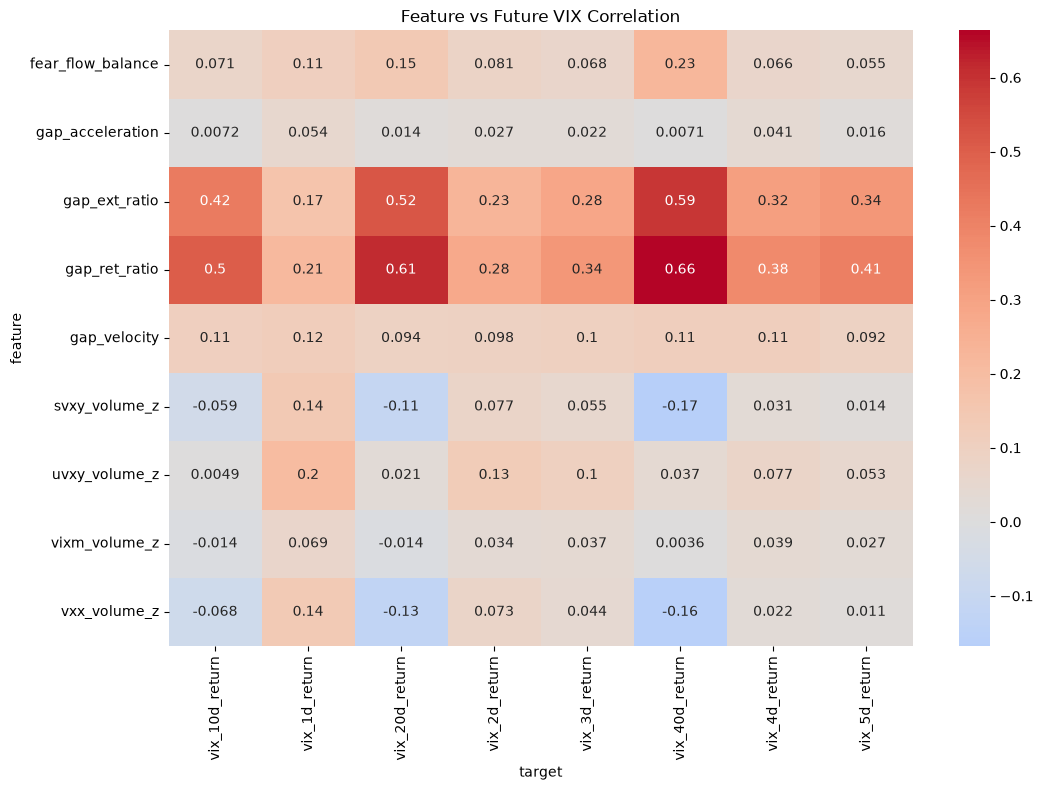

In [28]:
# 相関結果をピボットテーブルに変換してヒートマップを作成する
pivot_df = (
    correlation_summary_df
    .pivot(
        index="feature",
        columns="target",
        values="spearman"
    )
)
# ヒートマップを作成するための図を準備する
plt.figure(figsize=(12, 8))
# ヒートマップを作成する
sns.heatmap(
    pivot_df,
    annot=True,
    cmap="coolwarm",
    center=0
)
plt.title(
    "Feature vs Future VIX Correlation"
)
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"18_future_VIX_correlation_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
plt.show()

#### 19. 対数出来高特徴量作成

#### 目的

ETF毎の出来高水準の違いを吸収するため対数変換特徴量を作成する。

出来高の絶対値による影響を除去し、異常出来高そのものがシグナルとして機能するか確認する。

In [40]:
# 各フローETFの出来高の対数を計算する
FLOW_ETFS = [
    "uvxy",
    "svxy",
    "vxx"
]
# 各フローETFの出来高の対数を計算して新しい列に追加する
for etf in FLOW_ETFS:
    # 出来高の列名を作成する
    volume_col = f"{etf}_volume"
    # 出来高の対数を計算して新しい列に追加する
    research_df[f"{etf}_volume_log"] = np.log1p(research_df[volume_col])


#### 20. 対数出来高 Z-Score 作成

##### 目的

対数変換後も異常値検出を可能にするためZ-score化する。

###

In [41]:

# 各フローETFの出来高の対数のZスコアを計算する
for etf in FLOW_ETFS:
    # 出来高の対数の列名を作成する
    log_col = f"{etf}_volume_log"
    # Zスコアの列名を作成する
    mean_col = (
        research_df[log_col]
        .rolling(60)
        .mean()
    )
    # Zスコアの計算に使用する平均と標準偏差を計算する
    std_col = (
        research_df[log_col]
        .rolling(60)
        .std()
    )
    # Zスコアを計算して新しい列に追加する
    research_df[f"{etf}_volume_log_z"] = (research_df[log_col] - mean_col) / std_col


#### 21. Flow特徴量定義

##### 目的

出来高特徴量のみを評価対象とする。

In [42]:
# フローETFの特徴量を定義して統計量を表示する
FLOW_FEATURES = [
    "uvxy_volume_z",
    "svxy_volume_z",
    "vxx_volume_z",
    "uvxy_volume_log_z",
    "svxy_volume_log_z",
    "vxx_volume_log_z"
]
display(
    research_df[
        FLOW_FEATURES
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
uvxy_volume_z,2079.0,0.247399,1.172046,-1.867160,-0.564672,-0.027087,0.795854,6.665242
svxy_volume_z,2079.0,-0.000978,1.122841,-2.245090,-0.690819,-0.333714,0.367877,7.211510
vxx_volume_z,2020.0,0.269259,1.214679,-1.944556,-0.516547,-0.059724,0.697091,7.576463
uvxy_volume_log_z,2020.0,0.235323,1.088911,-4.221479,-0.518530,0.186617,0.953771,4.573667
svxy_volume_log_z,2020.0,-0.063061,1.100895,-3.867917,-0.840505,-0.201871,0.625525,4.730106
vxx_volume_log_z,2020.0,0.253188,1.112381,-3.448213,-0.509136,0.200260,0.937826,5.087067


#### 22. Flow相関分析

##### 目的

出来高特徴量が
何営業日先のVIXを説明するか確認する。

In [43]:
# フローETFの特徴量とターゲット列の相関を計算する
flow_correlation_results = []
# 各ターゲット列に対してフローETFの特徴量との相関を計算する
for target_col in TARGET_COLS:
    # 各フローETFの特徴量に対して相関を計算する
    for feature in FLOW_FEATURES:
        work_df = research_df[[feature, target_col]].dropna()
        # ピアソン相関の結果を計算
        pearson_corr, pearson_p = pearsonr(
            work_df[feature],
            work_df[target_col]
        )
        # スピアマン相関の結果を計算
        spearman_corr, spearman_p = spearmanr(
            work_df[feature],
            work_df[target_col]
        )
        # 計算結果を辞書にまとめてリストに追加
        flow_correlation_results.append({
            "feature": feature,
            "target": target_col,
            "pearson": pearson_corr,
            "spearman": spearman_corr,
            "pearson_p": pearson_p,
            "spearman_p": spearman_p
        })
# 計算結果をDataFrameに変換
flow_corr_df = pd.DataFrame(
    flow_correlation_results
)
display(flow_corr_df)

,feature,target,pearson,spearman,pearson_p,spearman_p
0,uvxy_volume_z,vix_1d_return,0.319020,0.203536,2.131326e-50,7.042046e-21
1,svxy_volume_z,vix_1d_return,0.289458,0.140983,2.057056e-41,1.070135e-10
2,vxx_volume_z,vix_1d_return,0.240312,0.139863,6.293489e-28,2.733164e-10
3,uvxy_volume_log_z,vix_1d_return,0.263244,0.195916,2.272532e-33,6.326809e-19
4,svxy_volume_log_z,vix_1d_return,0.224207,0.133778,1.967352e-24,1.579783e-09
5,vxx_volume_log_z,vix_1d_return,0.210851,0.139465,9.839561e-22,3.072328e-10
6,uvxy_volume_z,vix_2d_return,0.222193,0.130384,1.141992e-24,2.417692e-09
7,svxy_volume_z,vix_2d_return,0.216246,0.077335,2.016253e-23,4.165962e-04
8,vxx_volume_z,vix_2d_return,0.164923,0.072971,8.722855e-14,1.030824e-03
9,uvxy_volume_log_z,vix_2d_return,0.186251,0.125515,3.181191e-17,1.512633e-08


#### 24. ETF別イベントスタディ

##### 目的

異常出来高発生時の
将来VIX変化率を確認する。

In [44]:
# フローETFの特徴量が閾値を超えたイベントのターゲット列に対する将来リターンを計算する
THRESHOLD = 2.0
event_rows = []
# 各フローETFの特徴量に対して閾値を超えたイベントを抽出し、ターゲット列の将来リターンを計算する
for feature in [
    "uvxy_volume_z",
    "svxy_volume_z",
    "vxx_volume_z",
    "uvxy_volume_log_z",
    "svxy_volume_log_z",
    "vxx_volume_log_z"
]:
    # 閾値を超えたサンプルを抽出
    sample_df = research_df[
        research_df[feature]
        >= THRESHOLD
    ]
    # 各ターゲット列に対して将来リターンを計算
    for target_col in TARGET_COLS:
        # 将来リターンを計算するためのサンプルが存在するか確認
        event_rows.append({
            "feature": feature,
            "target": target_col,
            "count": len(sample_df),
            "future_return": sample_df[target_col].mean()
        })
# 将来リターンを計算したイベントをデータフレームに変換
event_df = pd.DataFrame(event_rows)
display(event_df)

,feature,target,count,future_return
0,uvxy_volume_z,vix_1d_return,164,0.095454
1,uvxy_volume_z,vix_2d_return,164,0.092563
2,uvxy_volume_z,vix_3d_return,164,0.085199
3,uvxy_volume_z,vix_4d_return,164,0.065000
4,uvxy_volume_z,vix_5d_return,164,0.074381
5,uvxy_volume_z,vix_10d_return,164,0.050764
6,uvxy_volume_z,vix_20d_return,164,0.083648
7,uvxy_volume_z,vix_40d_return,164,0.121959
8,svxy_volume_z,vix_1d_return,135,0.078414
9,svxy_volume_z,vix_2d_return,135,0.073427


#### 25. 出来高分位分析

##### 目的

出来高増加とVIX上昇率が
単調関係を持つか確認する。

In [45]:
# フローETFの特徴量に基づいてVIXの将来リターンをデシルごとに集計する
etf = "uvxy_volume_z"
# 集計対象のフローETFの特徴量を指定
work_df = research_df[
    [
        etf,
        "vix_1d_return",
        "vix_2d_return",
        "vix_3d_return",
        "vix_4d_return",
        "vix_5d_return"
    ]
].dropna()
# フローETFの特徴量をデシルに分割する
work_df["decile"] = pd.qcut(
    work_df[etf],
    q=10,
    labels=False
)
# デシルごとのVIXの将来リターンを計算する
result_df = (
    work_df
    .groupby("decile")
    [
        [
            "vix_1d_return",
            "vix_2d_return",
            "vix_3d_return",
            "vix_4d_return",
            "vix_5d_return"
        ]
    ]
    .mean()
)
display(result_df)

,vix_1d_return,vix_2d_return,vix_3d_return,vix_4d_return,vix_5d_return
decile,,,,,
0,-0.016167,-0.019738,-0.019138,-0.016757,-0.017148
1,-0.012915,-0.005608,-0.001416,0.002215,0.005923
2,-0.016384,-0.010356,-0.000872,0.001984,0.007805
3,-0.002216,-0.001486,0.003580,0.011105,0.019642
4,-0.014263,-0.010601,-0.012689,-0.007412,-0.004420
5,-0.000394,-0.003760,-0.002171,0.008986,0.006727
6,-0.000830,0.014933,0.030256,0.014467,0.025392
7,-0.000247,0.015159,0.010586,0.020757,0.007638
8,0.023206,0.018510,0.021101,0.030223,0.028519


#### 26. 単回帰分析

##### 目的

各出来高特徴量の
単独説明力(R²)を測定する。

In [46]:
# フローETFの特徴量に基づいて単回帰モデルを構築し、R2と調整済みR2を計算する
single_model_rows = []
# 各フローETFの特徴量とターゲット列の組み合わせに対して単回帰モデルを構築し、R2と調整済みR2を計算する
for feature in FLOW_FEATURES:
    # 各ターゲット列に対して単回帰モデルを構築
    for target_col in TARGET_COLS:
        # データフレームから欠損値を除外
        work_df = research_df[
            [
                feature,
                target_col
            ]
        ].dropna()
        # 説明変数と目的変数を設定
        X = sm.add_constant(work_df[[feature]])
        # 目的変数を設定
        y = work_df[target_col]
        # 単回帰モデルを構築
        model = sm.OLS(y, X).fit()
        # R2と調整済みR2を計算してリストに追加
        single_model_rows.append({
            "feature": feature,
            "target": target_col,
            "r2": model.rsquared,
            "adj_r2": model.rsquared_adj
        })
# 単回帰モデルの結果をデータフレームに変換
single_r2_df = pd.DataFrame(single_model_rows)
display(single_r2_df)

,feature,target,r2,adj_r2
0,uvxy_volume_z,vix_1d_return,0.101774,1.013412e-01
1,uvxy_volume_z,vix_2d_return,0.049370,4.891189e-02
2,uvxy_volume_z,vix_3d_return,0.024849,2.437962e-02
3,uvxy_volume_z,vix_4d_return,0.015545,1.507135e-02
4,uvxy_volume_z,vix_5d_return,0.013451,1.297594e-02
5,uvxy_volume_z,vix_10d_return,0.001101,6.196626e-04
6,uvxy_volume_z,vix_20d_return,0.000812,3.310359e-04
7,uvxy_volume_z,vix_40d_return,0.002431,1.950520e-03
8,svxy_volume_z,vix_1d_return,0.083786,8.334465e-02
9,svxy_volume_z,vix_2d_return,0.046762,4.630330e-02


#### 27. 単回帰R²ヒートマップ

##### 目的

どのETF出来高が
どの時間軸で有効か確認する。

saved: /workspace/data/figures/27_Simple_regression_R2_heatmap_2010-01-01_2026-10-23.png


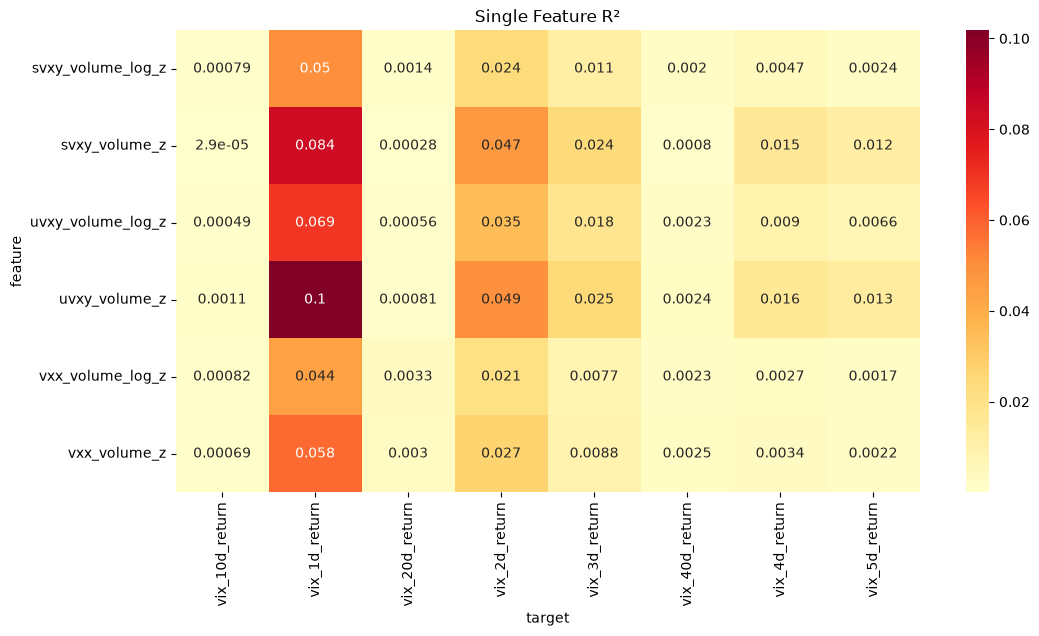

In [47]:
pivot_df = (
    single_r2_df
    .pivot(
        index="feature",
        columns="target",
        values="r2"
    )
)
plt.figure(
    figsize=(12, 6)
)
sns.heatmap(
    pivot_df,
    annot=True,
    cmap="YlOrRd"
)
plt.title("Single Feature R²")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"27_Simple_regression_R2_heatmap_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
plt.show()

#### 28. イベントスタディ設定

##### 目的

異常出来高イベント発生時の将来VIX挙動を評価する。

イベントの重複による統計的バイアスを防ぐため、クールダウン期間を導入する。

In [48]:
# イベントベースの特徴量、閾値、ターゲット、クールダウン日数を定義
EVENT_FEATURES = ["uvxy_volume_z", "svxy_volume_z", "vxx_volume_z"]
EVENT_THRESHOLDS = [1.0, 2.0, 3.0, 4.0]
EVENT_TARGETS = [
    "vix_1d_return",
    "vix_2d_return",
    "vix_3d_return",
    "vix_4d_return",
    "vix_5d_return"
]
COOLDOWN_DAYS = 5

#### 29. イベント抽出関数

##### 目的

連続イベントによる重複集計を防ぐ。

一度イベントを検出したら
次の5営業日は除外する。

In [49]:
def extract_events(
    df,
    feature_col,
    threshold,
    cooldown_days=5
):
    """
    Extract events from a DataFrame based on a feature column exceeding a threshold,
    with a cooldown period to avoid consecutive events.

    Parameters:
    df (pd.DataFrame): The input DataFrame.
    feature_col (str): The column name to check for events.
    threshold (float): The threshold value for the feature column.
    cooldown_days (int): The number of days to wait before considering another event.

    Returns:
    pd.DataFrame: A DataFrame containing only the rows where events occurred.
    """
    work_df = df.copy()
    event_idx = []
    last_event_idx = -999999
    # DataFrameのインデックスを反復処理し、しきい値とクールダウン期間に基づいてイベントを特定する。
    for idx in work_df.index:
        # 現在のインデックスに対応する特徴量の値を取得する。
        value = work_df.loc[idx, feature_col]
        # 値がNaNの場合はスキップする。
        if pd.isna(value):
            continue
        # 値が閾値未満の場合はスキップする。
        if value < threshold:
            continue
        # クールダウン期間内であればスキップする。
        if (idx - last_event_idx) <= cooldown_days:
            continue
        # イベントを記録する。
        event_idx.append(idx)
        # 最後のイベントのインデックスを更新する。
        last_event_idx = idx
    # イベントが発生した行のみを返す。
    return work_df.loc[event_idx]

#### 30. イベントスタディ (平均値・中央値)

##### 目的

異常出来高発生後の
将来VIXリターンを評価する。

In [50]:
# イベントスタディを実行する。
event_rows = []
# イベントスタディの結果を格納するリストを初期化する。
for feature in EVENT_FEATURES:
    # 各特徴量に対して閾値を適用してイベントを抽出する。
    for threshold in EVENT_THRESHOLDS:
        # 各閾値に対してイベントを抽出する。
        event_df = extract_events(
            research_df,
            feature,
            threshold,
            COOLDOWN_DAYS
        )
        # 各ターゲットに対してイベント統計を計算する。
        for target in EVENT_TARGETS:
            # イベント統計を辞書に追加する。
            event_rows.append({
                "feature": feature,
                "threshold": threshold,
                "target": target,
                "n_events": len(event_df),
                "mean": event_df[target].mean(),
                "median": event_df[target].median()
            })
# イベントスタディの結果をデータフレームに変換する。
event_study_df = pd.DataFrame(event_rows)
display(event_study_df)

,feature,threshold,target,n_events,mean,median
0,uvxy_volume_z,1.0,vix_1d_return,157,0.059800,0.042427
1,uvxy_volume_z,1.0,vix_2d_return,157,0.059903,0.032515
2,uvxy_volume_z,1.0,vix_3d_return,157,0.063120,0.034460
3,uvxy_volume_z,1.0,vix_4d_return,157,0.070086,0.044109
4,uvxy_volume_z,1.0,vix_5d_return,157,0.066206,0.019596
5,uvxy_volume_z,2.0,vix_1d_return,83,0.098577,0.075421
6,uvxy_volume_z,2.0,vix_2d_return,83,0.106492,0.067683
7,uvxy_volume_z,2.0,vix_3d_return,83,0.114523,0.077896
8,uvxy_volume_z,2.0,vix_4d_return,83,0.110121,0.080946
9,uvxy_volume_z,2.0,vix_5d_return,83,0.133882,0.076294


#### 30. イベントスタディ (平均値・中央値)

##### 目的

異常出来高発生後の
将来VIXリターンを評価する。

In [51]:
# イベントスタディを実行する。
event_rows = []
# イベントスタディの結果を格納するリストを初期化する。
for feature in EVENT_FEATURES:
    # 各特徴量に対して閾値を適用してイベントを抽出する。
    for threshold in EVENT_THRESHOLDS:
        # 各閾値に対してイベントを抽出する。
        event_df = extract_events(
            research_df,
            feature,
            threshold,
            COOLDOWN_DAYS
        )
        # 各ターゲットに対してイベント統計を計算する。
        for target in EVENT_TARGETS:
            # イベント統計を辞書に追加する。
            event_rows.append({
                "feature": feature,
                "threshold": threshold,
                "target": target,
                "n_events": len(event_df),
                "mean": event_df[target].mean(),
                "median": event_df[target].median()
            })
# イベントスタディの結果をデータフレームに変換する。
event_study_df = pd.DataFrame(event_rows)
display(event_study_df)

,feature,threshold,target,n_events,mean,median
0,uvxy_volume_z,1.0,vix_1d_return,157,0.059800,0.042427
1,uvxy_volume_z,1.0,vix_2d_return,157,0.059903,0.032515
2,uvxy_volume_z,1.0,vix_3d_return,157,0.063120,0.034460
3,uvxy_volume_z,1.0,vix_4d_return,157,0.070086,0.044109
4,uvxy_volume_z,1.0,vix_5d_return,157,0.066206,0.019596
5,uvxy_volume_z,2.0,vix_1d_return,83,0.098577,0.075421
6,uvxy_volume_z,2.0,vix_2d_return,83,0.106492,0.067683
7,uvxy_volume_z,2.0,vix_3d_return,83,0.114523,0.077896
8,uvxy_volume_z,2.0,vix_4d_return,83,0.110121,0.080946
9,uvxy_volume_z,2.0,vix_5d_return,83,0.133882,0.076294


#### 31. 対照群作成

##### 目的

異常出来高が発生していない
通常時データを作成する。

In [52]:
# コントロールグループの統計を計算するための準備を行う。
control_rows = []
# コントロールグループの統計を計算する。
for feature in EVENT_FEATURES:
    # 各特徴量に対してコントロールグループを抽出する。
    control_df = research_df[research_df[feature] < 1.0]
    # 各ターゲットに対してコントロールグループの統計を計算する。
    for target in EVENT_TARGETS:
        # コントロールグループの統計を辞書に追加する。
        control_rows.append({
            "feature": feature,
            "target": target,
            "count": len(control_df),
            "mean": control_df[target].mean(),
            "median": control_df[target].median()
        })
# コントロールグループの統計をDataFrameに変換する。
control_df_summary = pd.DataFrame(control_rows)
display(control_df_summary)

,feature,target,count,mean,median
0,uvxy_volume_z,vix_1d_return,1634,-0.007667,-0.011600
1,uvxy_volume_z,vix_2d_return,1634,-0.003031,-0.014035
2,uvxy_volume_z,vix_3d_return,1634,0.000833,-0.012538
3,uvxy_volume_z,vix_4d_return,1634,0.004474,-0.014320
4,uvxy_volume_z,vix_5d_return,1634,0.006925,-0.015715
5,svxy_volume_z,vix_1d_return,1783,-0.004547,-0.009368
6,svxy_volume_z,vix_2d_return,1783,-0.000204,-0.011932
7,svxy_volume_z,vix_3d_return,1783,0.001819,-0.010972
8,svxy_volume_z,vix_4d_return,1783,0.005293,-0.012771
9,svxy_volume_z,vix_5d_return,1783,0.007874,-0.013450


#### 32. イベント群と対照群の比較

##### 目的

通常時に対して
異常出来高イベント時のVIX変化率が
上昇しているか確認する。

In [53]:
# イベントスタディの結果とコントロールグループの統計を比較する。
comparison_rows = []
# 各特徴量に対してイベントスタディの結果とコントロールグループの統計を比較する。
for feature in EVENT_FEATURES:
    # コントロールグループの平均を取得する。
    control_mean = (
        control_df_summary[
            control_df_summary["feature"]
            == feature
        ]
        .set_index("target")
        ["mean"]
        .to_dict()
    )
    # 各イベントスタディの行に対して比較を行う。
    for _, row in (
        event_study_df.iterrows()
    ):
        # 対応する特徴量でない場合はスキップする。
        if row["feature"] != feature:
            continue
        # 対応するターゲットがコントロールグループに存在しない場合はスキップする。
        comparison_rows.append({
            "feature": feature,
            "threshold": row["threshold"],
            "target": row["target"],
            "event_mean": row["mean"],
            "control_mean": control_mean[row["target"]],
            "mean_diff": row["mean"] - control_mean[row["target"]]
        })
# 比較結果のデータフレームを作成する。
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,feature,threshold,target,event_mean,control_mean,mean_diff
0,uvxy_volume_z,1.0,vix_1d_return,0.059800,-0.007667,0.067467
1,uvxy_volume_z,1.0,vix_2d_return,0.059903,-0.003031,0.062935
2,uvxy_volume_z,1.0,vix_3d_return,0.063120,0.000833,0.062287
3,uvxy_volume_z,1.0,vix_4d_return,0.070086,0.004474,0.065612
4,uvxy_volume_z,1.0,vix_5d_return,0.066206,0.006925,0.059281
5,uvxy_volume_z,2.0,vix_1d_return,0.098577,-0.007667,0.106244
6,uvxy_volume_z,2.0,vix_2d_return,0.106492,-0.003031,0.109524
7,uvxy_volume_z,2.0,vix_3d_return,0.114523,0.000833,0.113690
8,uvxy_volume_z,2.0,vix_4d_return,0.110121,0.004474,0.105646
9,uvxy_volume_z,2.0,vix_5d_return,0.133882,0.006925,0.126957


#### 33. VIX急騰確率分析

##### 目的

異常出来高発生後に

- VIX +5%
- VIX +10%
- VIX +20%

が発生する確率を集計する。

In [54]:
# イベントスタディに基づく確率の計算
probability_rows = []
# 各特徴量、閾値、ターゲットに対してイベントの発生確率を計算する。
for feature in EVENT_FEATURES:
    # 各閾値に対してイベントを抽出する。
    for threshold in EVENT_THRESHOLDS:
        # イベントを抽出する。
        event_df = extract_events(
            research_df,
            feature,
            threshold,
            COOLDOWN_DAYS
        )
        # 各ターゲットに対して確率を計算する。
        for target in EVENT_TARGETS:
            # 対応するターゲットのデータを抽出する。
            sample = event_df[target].dropna()
            # サンプルが存在しない場合はスキップする。
            if len(sample) == 0:
                continue
            # イベントの発生確率を計算する。
            probability_rows.append({
                "feature": feature,
                "threshold": threshold,
                "target": target,
                "n_events": len(sample),
                "p_gt_5pct": (sample > 0.05).mean(),
                "p_gt_10pct": (sample > 0.10).mean(),
                "p_gt_20pct": (sample > 0.20).mean()
            })
# 確率データフレームを作成する。
probability_df = pd.DataFrame(probability_rows)
display(probability_df)

,feature,threshold,target,n_events,p_gt_5pct,p_gt_10pct,p_gt_20pct
0,uvxy_volume_z,1.0,vix_1d_return,157,0.471338,0.286624,0.108280
1,uvxy_volume_z,1.0,vix_2d_return,157,0.426752,0.280255,0.140127
2,uvxy_volume_z,1.0,vix_3d_return,157,0.452229,0.350318,0.171975
3,uvxy_volume_z,1.0,vix_4d_return,157,0.490446,0.401274,0.197452
4,uvxy_volume_z,1.0,vix_5d_return,157,0.433121,0.324841,0.171975
5,uvxy_volume_z,2.0,vix_1d_return,83,0.662651,0.457831,0.144578
6,uvxy_volume_z,2.0,vix_2d_return,83,0.566265,0.397590,0.228916
7,uvxy_volume_z,2.0,vix_3d_return,83,0.542169,0.421687,0.240964
8,uvxy_volume_z,2.0,vix_4d_return,83,0.542169,0.445783,0.240964
9,uvxy_volume_z,2.0,vix_5d_return,83,0.542169,0.385542,0.253012


#### 34. 急騰確率ヒートマップ

##### 目的

異常出来高の強さと
VIX急騰確率の関係を可視化する。

saved: /workspace/data/figures/34_Surge_Probability_Heatmap_2010-01-01_2026-10-23.png


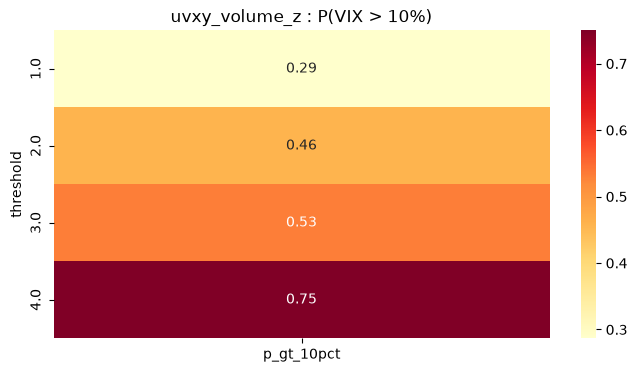

In [55]:
# 特定の特徴量とターゲットに対するイベント発生確率のヒートマップを作成する
target = "vix_1d_return"
feature = "uvxy_volume_z"
# 対象の特徴量とターゲットを指定する
plot_df = probability_df[
    (probability_df["feature"] == feature)
    &
    (probability_df["target"] == target)
]
# ピボットテーブルを作成して、閾値ごとの確率を整理する
pivot_df = plot_df.pivot_table(
    index="threshold",
    values="p_gt_10pct"
)
# ヒートマップを作成する
plt.figure(figsize=(8, 4))
# ヒートマップを描画する
sns.heatmap(pivot_df, annot=True, cmap="YlOrRd")
# タイトルを設定する
plt.title(f"{feature} : P(VIX > 10%)")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"34_Surge_Probability_Heatmap_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
plt.show()

#### 35. イベントスタディ結論テーブル

##### 目的

各ETFについて

- 閾値上昇
- 平均リターン上昇
- 急騰確率上昇

が単調に発生するか確認する。

In [ ]:
# 
for feature in EVENT_FEATURES:
    # Display the sorted probability dataframe for the current feature
    print("=" * 100)
    print(feature)
    display(
        probability_df[probability_df["feature"] == feature]
        .sort_values(["target", "threshold"])
    )

uvxy_volume_z


,feature,threshold,target,n_events,p_gt_5pct,p_gt_10pct,p_gt_20pct
0,uvxy_volume_z,1.0,vix_1d_return,157,0.471338,0.286624,0.108280
5,uvxy_volume_z,2.0,vix_1d_return,83,0.662651,0.457831,0.144578
10,uvxy_volume_z,3.0,vix_1d_return,47,0.723404,0.531915,0.170213
15,uvxy_volume_z,4.0,vix_1d_return,24,0.875000,0.750000,0.333333
1,uvxy_volume_z,1.0,vix_2d_return,157,0.426752,0.280255,0.140127
6,uvxy_volume_z,2.0,vix_2d_return,83,0.566265,0.397590,0.228916
11,uvxy_volume_z,3.0,vix_2d_return,47,0.531915,0.404255,0.255319
16,uvxy_volume_z,4.0,vix_2d_return,24,0.750000,0.541667,0.375000
2,uvxy_volume_z,1.0,vix_3d_return,157,0.452229,0.350318,0.171975
7,uvxy_volume_z,2.0,vix_3d_return,83,0.542169,0.421687,0.240964


svxy_volume_z


,feature,threshold,target,n_events,p_gt_5pct,p_gt_10pct,p_gt_20pct
20,svxy_volume_z,1.0,vix_1d_return,120,0.450000,0.316667,0.083333
25,svxy_volume_z,2.0,vix_1d_return,61,0.606557,0.475410,0.114754
30,svxy_volume_z,3.0,vix_1d_return,31,0.612903,0.548387,0.225806
35,svxy_volume_z,4.0,vix_1d_return,15,0.666667,0.666667,0.266667
21,svxy_volume_z,1.0,vix_2d_return,120,0.383333,0.241667,0.166667
26,svxy_volume_z,2.0,vix_2d_return,61,0.459016,0.377049,0.245902
31,svxy_volume_z,3.0,vix_2d_return,31,0.580645,0.483871,0.322581
36,svxy_volume_z,4.0,vix_2d_return,15,0.733333,0.666667,0.466667
22,svxy_volume_z,1.0,vix_3d_return,120,0.433333,0.333333,0.225000
27,svxy_volume_z,2.0,vix_3d_return,61,0.475410,0.360656,0.213115


vxx_volume_z


,feature,threshold,target,n_events,p_gt_5pct,p_gt_10pct,p_gt_20pct
40,vxx_volume_z,1.0,vix_1d_return,137,0.430657,0.226277,0.058394
45,vxx_volume_z,2.0,vix_1d_return,88,0.568182,0.386364,0.125000
50,vxx_volume_z,3.0,vix_1d_return,53,0.622642,0.433962,0.132075
55,vxx_volume_z,4.0,vix_1d_return,29,0.724138,0.655172,0.241379
41,vxx_volume_z,1.0,vix_2d_return,137,0.394161,0.262774,0.145985
46,vxx_volume_z,2.0,vix_2d_return,88,0.556818,0.340909,0.215909
51,vxx_volume_z,3.0,vix_2d_return,53,0.566038,0.415094,0.264151
56,vxx_volume_z,4.0,vix_2d_return,29,0.655172,0.586207,0.344828
42,vxx_volume_z,1.0,vix_3d_return,137,0.423358,0.306569,0.145985
47,vxx_volume_z,2.0,vix_3d_return,88,0.511364,0.397727,0.238636


: 

# VIX関連ETF出来高検証メモ

## 検証概要

UVXY・SVXY・VXXの出来高(Z-score)を説明変数とし、将来のVIXリターンとの関係を検証した。

---

## 単回帰分析結果

単回帰では短期(1〜3営業日)にのみ説明力が確認された。

| Feature | VIX 1日後 R² |
|----------|----------:|
| UVXY | 0.102 |
| SVXY | 0.084 |
| VXX | 0.058 |

一方で10営業日以降の説明力はほぼ消失した。

この結果から、ETF出来高は中長期VIXの予測には不向きであり、短期シグナルとしてのみ有効と考えられる。

---

## 対数変換の評価

出来高を対数変換した場合、

- UVXY: 0.102 → 0.069
- SVXY: 0.084 → 0.050
- VXX: 0.058 → 0.044

と説明力が低下した。

出来高スパイクそのものがシグナルになっており、対数変換による外れ値圧縮は有益ではないと考えられる。

---

## イベントスタディ結果

出来高閾値上昇に伴い、VIX急騰確率は明確に上昇した。

UVXYの例：

| UVXY Z-score | 翌日VIX+10%以上 |
|-------------|---------------:|
| >=1 | 28.7% |
| >=2 | 45.8% |
| >=3 | 53.2% |
| >=4 | 75.0% |

また、

| UVXY Z-score | 翌日VIX+20%以上 |
|-------------|---------------:|
| >=1 | 10.8% |
| >=2 | 14.5% |
| >=3 | 17.0% |
| >=4 | 33.3% |

となり、閾値上昇と急騰確率上昇の単調関係が確認された。

SVXY・VXXでも同様の傾向が観測された。

---

## 現時点での結論

ETF出来高は、

- VIXリターンを高精度に回帰予測する変数ではない
- 一方でVIX急騰イベントの発生確率を示す警戒シグナルとして機能する

可能性が高い。

特にUVXYの出来高スパイクは有力な先行シグナル候補である。

---

## 今後の方針

次フェーズでは、

- VIX +10%以上
- VIX +20%以上

を目的変数とした分類問題として再定義し、

- Precision
- Recall
- ROC-AUC
- Lift

を評価する。

出来高の連続値予測ではなく、

「VIX急騰警報システム」としての有効性を検証する。